# Two spins in a field: Hamiltonian simulation in short

[![Run on Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/ENCCS/eurohpc-qdevices/main?urlpath=doc/tree/examples/hamiltonian/two_spins/two_spins.ipynb)

Two spins, one Hamiltonian, one time. We solve the evolution exactly in QuTiP, the Quantum Toolbox in Python, write it as gates, build the same circuit in Qrisp, a high-level language for building quantum algorithms, and read what the quantum computer Euro-Q-Exa gave for it. To try it yourself: **Run > Run All Cells** emulates all of it on this page, and nothing is sent. Why this model: the Ising model in a transverse field describes real magnets, its field term is the driver of quantum annealing, and one Trotter step of it has the shape of one layer of QAOA, an optimisation algorithm. Section 5, after the run, says where, with sources. Two spins are few enough to follow every step exactly.

*Hamiltonian simulation* is what the quantum computer does: it applies the evolution of a physical system to its qubits. *Emulation* is what this page does: a classical computer computes what the quantum computer would do with the same circuit.

This page is the short start. The [long tutorial](../tutorial.ipynb) takes the same path in more depth, on to three qubits and the hydrogen molecule.

In [1]:
import importlib.util, json, os, sys
from pathlib import Path
import numpy as np

if not os.path.exists("spins.py"):
    raise SystemExit("Open this page from examples/hamiltonian/two_spins/ of a clone, where its files are.")
sys.path[:0] = [os.getcwd(), os.path.abspath("../../tools"), os.path.abspath("../../qrisp")]

## 1. The model in QuTiP

The model is the Ising model in a transverse field, here on two spins:

$$H = -J\,Z_0 Z_1 - h\,(X_0 + X_1), \qquad J = 1,\; h = 1.2 .$$

$Z_k$ and $X_k$ are Pauli operators on spin $k$. The coupling $-J Z_0Z_1$ lowers the energy when the two spins point the same way along $z$. The field $h$ points along $x$, across that axis, and turns each spin away from it. The two terms do not commute, and in a long chain their competition gives a quantum phase transition.

With $\hbar = 1$, the state at time $t$ is $|\psi(t)\rangle = e^{-iHt}|00\rangle$: both spins start in $|0\rangle$, along $+z$.

A *shot* is one run of the circuit on the machine, ending in one reading of the qubits. Its *key* is the bit string read, `q[1] q[0]`, as the machine returns it. The *share* of a key is the fraction of shots that give it; on a perfect machine it is $|\langle \mathrm{key}|\psi(t)\rangle|^2$. The cell builds $H$ as a QuTiP operator and prints its four levels.

In [2]:
from spins import exact, hamiltonian, over_time, chart
from trotter import T

H = hamiltonian()
print(H)
print("The four levels:", np.round(H.eigenenergies(), 6))

Quantum object: dims=[[2, 2], [2, 2]], shape=(4, 4), type='oper', dtype=CSR, isherm=True
Qobj data =
[[-1.  -1.2 -1.2  0. ]
 [-1.2  1.   0.  -1.2]
 [-1.2  0.   1.  -1.2]
 [ 0.  -1.2 -1.2 -1. ]]
The four levels: [-2.6 -1.   1.   2.6]


*On a first read you can skip to the chart.*

In the basis of $X$ the field term is diagonal and $Z_0Z_1$ swaps $|{+}{+}\rangle$ with $|{-}{-}\rangle$ and $|{+}{-}\rangle$ with $|{-}{+}\rangle$. So $H$ falls into two blocks of $2\times2$: one with the levels $\pm\sqrt{J^2+4h^2} = \pm 2.6$, one with $\pm J = \pm 1$. The start $|00\rangle$ has weight in both.

The jobs stop at $t = 2\pi/2.6$. There the phases of the first block have made one full turn, and only the second block has changed the state. The amplitude of `11` is then $(1 - e^{iJt})/2$, so its share is $\sin^2(Jt/2) = 0.874$, and `01` and `10` are exactly zero. The chart solves the Schrödinger equation with QuTiP's `sesolve`; the cell then compares it at $t$ with the propagator $e^{-iHt}$.

By the propagator at t = 2π/2.6: {'00': 0.125745, '01': 0.0, '10': 0.0, '11': 0.874255}
By sesolve at the same time:    {'00': 0.125745, '01': 0.0, '10': 0.0, '11': 0.874255}


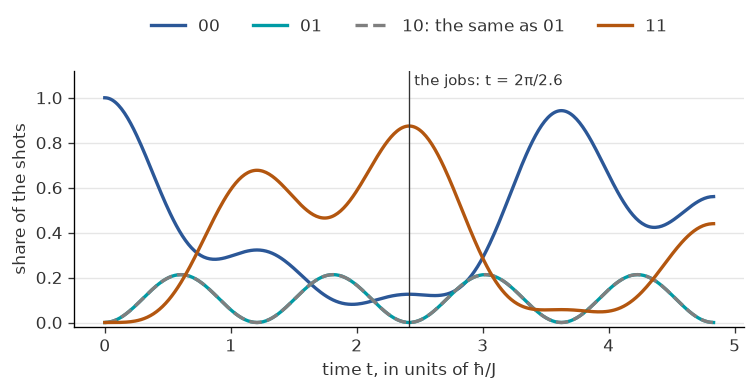

In [3]:
times = np.linspace(0, 2 * T, 401)
curves = over_time(times)
chart(times, curves)

print("By the propagator at t = 2π/2.6:", {key: round(v, 6) for key, v in exact().items()})
print("By sesolve at the same time:   ", {key: round(float(c[200]), 6) for key, c in curves.items()})

`11` leads at $t = 2\pi/2.6$, at its highest share in the chart, and the curves of `01` and `10` lie on each other: the model does not change when the two spins swap. The two routes agree to six places.

## 2. One Trotter step as gates

Write $H = A + B$, with $A = -J Z_0Z_1$ and $B = -h(X_0 + X_1)$. $Z$ and $X$ do not commute, so $e^{-iHt} \neq e^{-iBt}e^{-iAt}$. For a short step $dt = t/N$ the difference is small: $N$ steps of $e^{-iB\,dt}e^{-iA\,dt}$ are the first-order product formula, also called Trotter steps, with an error of order $dt^2$ a step.

Each factor is a short circuit. Here $R_z(a) = e^{-iaZ/2}$, and CX, also called CNOT, flips its second qubit when its first is 1.

- **The $ZZ$ term.** A CX moves $Z$ of its target to both qubits: $\mathrm{CX}\,(I\otimes Z)\,\mathrm{CX} = Z\otimes Z$. So CX, then $R_z(a)$ on `q[1]`, then CX, is $e^{-iaZ_0Z_1/2}$; for $e^{-iA\,dt}$, $a = -2J\,dt$.
- **The $X$ terms.** The Hadamard gate, written H in the circuits and $\mathrm{Had}$ here to keep it apart from the Hamiltonian $H$, turns $Z$ into $X$: $\mathrm{Had}\,Z\,\mathrm{Had} = X$. So H, $R_z(a)$, H is $e^{-iaX/2}$; for each spin $a = -2h\,dt$. The two $X$ terms commute, so no further split is needed.

One step is 2 CX and 7 one-qubit gates. The cell checks both identities with QuTiP at an angle of 0.7.

In [4]:
from spins import gates_against_exponentials

zz_gap, x_gap = gates_against_exponentials()
print(f"CX, RZ, CX less exp(-i a ZZ/2): {zz_gap:.1e};  H, RZ, H less exp(-i a X/2): {x_gap:.1e}")

CX, RZ, CX less exp(-i a ZZ/2): 0.0e+00;  H, RZ, H less exp(-i a X/2): 2.2e-16


Here is the first step of the job STEPS5, drawn by `qutip-qip`, the quantum information processing package of QuTiP, from the text that was sent. Orange marks a gate on two qubits. RZ shows its angle: $-0.97 = -2J\,dt$ and $-1.16 = -2h\,dt$, with $dt = t/5$. The meters on the right are the two measurements.

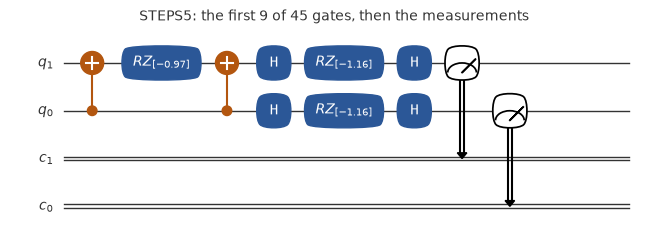

In [5]:
from circuit import Circuit

steps5 = Circuit.of_text(Path("STEPS5.qasm").read_text())
if importlib.util.find_spec("qutip_qip"):
    from pictures import circuit_figure
    circuit_figure(steps5, most=9, title="STEPS5");
else:
    print("qutip-qip is not installed here, so this drawing is left out.")

The text that was sent is OpenQASM 2: a header of four lines, then one gate a line on named qubits, then the measurements. Here are its first step and its end.

In [6]:
lines = Path("STEPS5.qasm").read_text().splitlines()
print("\n".join(lines[:13] + ["..."] + lines[-2:]))

OPENQASM 2.0;
include "qelib1.inc";
qreg q[2];
creg c[2];
cx q[0],q[1];
rz(-0.9666438934122439) q[1];
cx q[0],q[1];
h q[1];
h q[0];
rz(-1.1599726720946928) q[1];
rz(-1.1599726720946928) q[0];
h q[1];
h q[0];
...
measure q[0] -> c[0];
measure q[1] -> c[1];


The two jobs of this folder take 5 and 16 steps to the same $t$. The cell gives the size of each text and what a perfect machine gives for it, by our emulator of the text and by QuTiP from the same product of exponentials. $\lVert V - e^{-iHt}\rVert$ is the largest error of the $N$ steps $V$ on any state; the last two lines show how it falls with $N$.

In [7]:
from emulate import top
from spins import error, trotter

for steps in (5, 16):
    job = Circuit.of_text(Path(f"STEPS{steps}.qasm").read_text())
    print(f"STEPS{steps}: {job.size};  error {error(steps):.3f}")
    print("   our emulator of the text:", top(job.shares()))
    print("   QuTiP, the same steps:   ", top(trotter(steps)))
print("Exact, with no Trotter error:", top(exact()))
print("N*N times the error, for N = 8, 16, 32 and 64:", [round(error(n) * n * n, 2) for n in (8, 16, 32, 64)])
print("At t = 1, the error of 5 steps over that of 16:", round(error(5, 1.0) / error(16, 1.0), 1))

STEPS5: qubits read 2, gates 45, two-qubit gates 10;  error 0.236
   our emulator of the text: 11: 0.866  00: 0.108  01: 0.013  10: 0.013
   QuTiP, the same steps:    11: 0.866  00: 0.108  01: 0.013  10: 0.013
STEPS16: qubits read 2, gates 144, two-qubit gates 32;  error 0.021
   our emulator of the text: 11: 0.877  00: 0.123  01: 0.000  10: 0.000
   QuTiP, the same steps:    11: 0.877  00: 0.123  01: 0.000  10: 0.000
Exact, with no Trotter error: 11: 0.874  00: 0.126  01: 0.000  10: 0.000
N*N times the error, for N = 8, 16, 32 and 64: [5.47, 5.27, 5.23, 5.21]
At t = 1, the error of 5 steps over that of 16: 3.3


## 3. The same in Qrisp

Qrisp writes the texts of this folder. The function `ising2` in [`qrisp/programs.py`](../../qrisp/programs.py) builds $H$ from Qrisp's operators and hands it to `trotterization`, which writes the same first-order steps. Qrisp turns them into gates, and `qasm2.py` writes the text in OpenQASM 2. The cell prints the function, writes both texts again, and compares their SHA-256 with the manifest. It then runs Qrisp's own emulator. Where Qrisp is not installed it says so.

In [8]:
manifest = {job["name"]: job for job in json.loads(Path("manifest.json").read_text())["jobs"]}

if importlib.util.find_spec("qrisp"):
    from by_qrisp import emulated, sha256, source, text
    print(source())
    for steps in (5, 16):
        same = sha256(text(steps)) == manifest[f"STEPS{steps}"]["sha256"]
        print(f"STEPS{steps}: the text Qrisp writes now is the text in the manifest: {same}")
    print("Qrisp's emulator, 5 steps:", emulated(5))
else:
    print("Qrisp is not installed here, so this cell is left out.")

def ising2(t: float = 2 * pi / 2.6, steps: int = 5) -> QuantumVariable:
    """Two spins of the Ising model in a field, J = 1, field 1.2, first order, by Qrisp's trotterization."""
    ham = -1.0 * Z(0) * Z(1) - 1.2 * (X(0) + X(1))
    qv = QuantumVariable(2)
    ham.trotterization()(qv, t=t, steps=steps)
    return qv



STEPS5: the text Qrisp writes now is the text in the manifest: True
STEPS16: the text Qrisp writes now is the text in the manifest: True
Qrisp's emulator, 5 steps: {'11': 0.866089, '00': 0.107571, '10': 0.01317, '01': 0.01317}


Qrisp's emulator gives the shares of our emulator and of QuTiP to about five places. Its labels read `q[0]` first, where a key reads `q[1]` first; on these two spins `01` and `10` hold the same share, so here the two orders agree.

## 4. The run on Euro-Q-Exa

Both texts went to Euro-Q-Exa through the app `qdevices`, 1000 shots each, seconds apart on one evening; STEPS5 was sent as the example [`qrisp/ising2`](../../qrisp/ising2/README.md). The site compiles each text into the machine's own gates and places it on its qubits. `results.json` holds the counts. The shot error of a share $p$ from $n$ shots is $\sqrt{p(1-p)/n}$.

In [9]:
from machine import reads

read = reads(Path("."))
for name, job in read.items():
    print(f"{name}: {job.counts};  11 read {job.share('11'):.3f}, shot error {job.error('11'):.3f}")

STEPS5: {'00': 95, '01': 67, '10': 55, '11': 783};  11 read 0.783, shot error 0.013
STEPS16: {'00': 113, '01': 53, '10': 45, '11': 789};  11 read 0.789, shot error 0.013


## 5. Why this example, and where it applies

Where the model of section 1 is used:

- **Real magnets.** LiHoF$_4$ is a dipolar Ising ferromagnet; a field across its Ising axis turns its thermal transition into a quantum transition at zero temperature (Bitko, Rosenbaum and Aeppli). In CoNb$_2$O$_6$, a quasi-one-dimensional Ising ferromagnet, strong transverse fields tune the chain through its critical point (Coldea et al.).
- **Quantum annealing.** The transverse field supplies quantum fluctuations and is changed over time, as the temperature is in simulated annealing (Kadowaki and Nishimori).
- **QAOA**, the quantum approximate optimisation algorithm. Each layer applies a phase from a diagonal cost, for the MaxCut problem on a graph a sum of $ZZ$ terms up to a constant, then $e^{-i\beta B}$ with $B$ the sum of $X$ on every qubit (Farhi, Goldstone and Gutmann). One Trotter step of section 2 has that shape; the folder [`qrisp/qaoa_maxcut`](../../qrisp/qaoa_maxcut/README.md) holds one layer of it.
- **Digital quantum simulation.** Two spins of this model, by Trotter steps, ran on two superconducting qubits (Salathé et al.), and a range of spin models on up to six trapped-ion qubits, with up to 100 gates (Lanyon et al.).

Two spins are solved exactly on any laptop, as this page does; the magnets, annealing and QAOA above need many spins, and the experiments above, on two and up to six qubits, showed the method. The point here is the steps, which carry over to large sizes: the Hamiltonian as Pauli terms, its exact evolution, a product formula, the gates of each term, the text the machine gets, and how to read what comes back.

## 6. What it shows

The first chart sets the sources side by side for each key of STEPS5: a perfect machine (our emulator of the text), the stored files of QuTiP and Qrisp where this folder holds them, and the machine, with a bar of one shot error each way. The second does the same for the key `11` of both jobs.

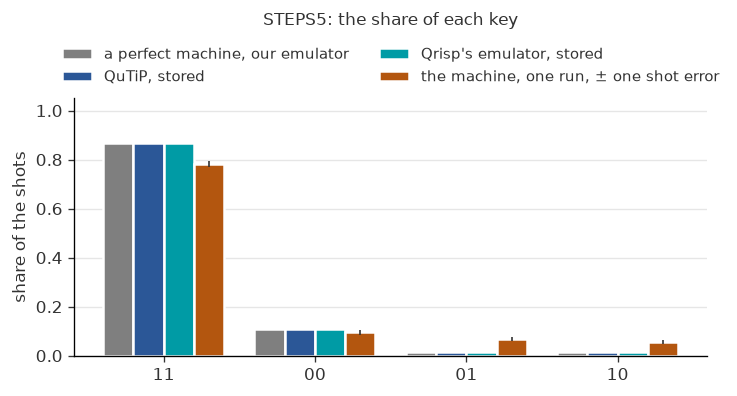

In [10]:
from pictures import folder_outcomes, outcomes_figure

outcomes = folder_outcomes(Path("."))
outcomes_figure(outcomes[:1], title="STEPS5: the share of each key");

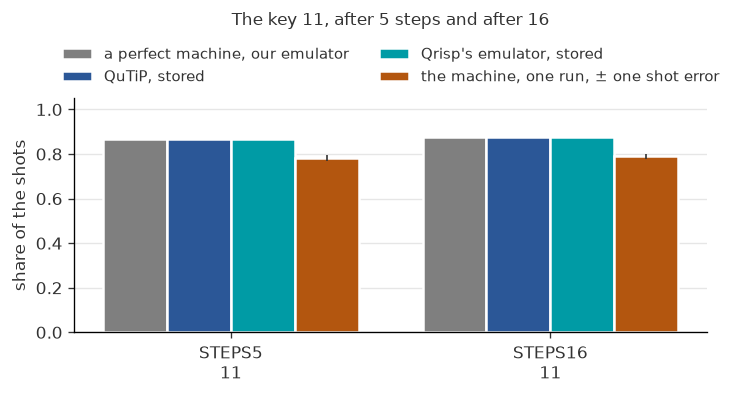

In [11]:
outcomes_figure(outcomes, title="The key 11, after 5 steps and after 16");

**The Trotter error.** With no Trotter error `11` holds 0.874, and `01` and `10` hold nothing. 5 steps give 0.866 and put 0.013 on each of `01` and `10`: at this time those two keys are the mark of the product formula. 16 steps give 0.877, with 0.0001 on each. The largest error on any state falls from 0.236 to 0.021, about 11 times for 3.2 times the steps. At this time it falls as $1/N^2$: $N^2$ times the error stays between 5.2 and 5.5 from 8 to 64 steps. At $t = 1$ it falls about as $1/N$, as an error of order $dt^2$ a step (section 2) leads one to expect: 16 steps in place of 5 cut it 3.3 times.

**The machine's reading.** STEPS5 read `11` in 0.783 of the shots, with a shot error of 0.013, against 0.866 on a perfect machine. So the machine lost about 0.083 of the answer, where the formula lost 0.008. `01` and `10` read 0.122 together, where a perfect machine gives 0.026: most of those shots come from the machine's errors, not from the formula.

**16 steps read the same as 5:** 0.789 and 0.783, 0.006 apart, where the shot error of that difference is 0.018. The text of STEPS16 has 32 CX, that of STEPS5 10. A simple model, ours, gives the scale of what 32 CX would cost if all of them ran: each two-qubit gate keeps the answer with the same chance, and a shot it loses lands on any of the four keys with equal chance. The cell sets that chance so that the 10 CX of STEPS5 read 0.783. The model puts all the loss on the gates and none on the readout, so read its answer as a scale, not a prediction. If the readout took 0.03 to 0.07 of the shots in the same way and the gates the rest, the model would still put STEPS16 between 0.08 and 0.12 below what was read, 6 to 9 shot errors; the cell prints these too. On the same machine, less than a minute earlier on the same evening, the three-qubit chain of the long tutorial fell from 0.474 to 0.190 as its text went from 18 to 34 two-qubit gates: there, more gates in the text did read lower.

In [12]:
from machine import SameLoss

perfect = {n: Circuit.of_text(Path(f"STEPS{n}.qasm").read_text()).shares()["11"] for n in (5, 16)}
five, sixteen = read["STEPS5"], read["STEPS16"]
model = SameLoss(perfect[5], five.share("11"), 10)
alone = model.share(perfect[16], 32)
print(f"Each CX keeps the answer with chance {model.kept:.3f}; with all 32 CX, STEPS16 would read {alone:.2f}.")
print(f"It read {sixteen.share('11'):.3f}, {sixteen.share('11') - alone:.2f} above that; "
      f"one shot error is {sixteen.error('11'):.3f}.")
for readout in (0.97, 0.95, 0.93):
    share = SameLoss(perfect[5], five.share("11"), 10, readout).share(perfect[16], 32)
    gap = sixteen.share("11") - share
    print(f"If the readout keeps {readout} of the shots: {share:.2f}, {gap:.2f} or {gap / sixteen.error('11'):.0f} "
          "shot errors below what was read.")

Each CX keeps the answer with chance 0.986; with all 32 CX, STEPS16 would read 0.64.
It read 0.789, 0.14 above that; one shot error is 0.013.
If the readout keeps 0.97 of the shots: 0.67, 0.12 or 9 shot errors below what was read.
If the readout keeps 0.95 of the shots: 0.69, 0.10 or 8 shot errors below what was read.
If the readout keeps 0.93 of the shots: 0.71, 0.08 or 6 shot errors below what was read.


*On a first read you can skip to the end of this section: the next cell prints the answer.*

**Why the same.** On two qubits every product of gates, however long, is one $4\times4$ unitary. Any such unitary can be written with at most 3 CX and one-qubit gates (Vidal and Dawson). Shende, Bullock and Markov give a test of how many it needs, from the characteristic polynomial of $\gamma(U) = U\,(Y\otimes Y)\,U^T(Y\otimes Y)$, with $U$ first scaled to determinant 1: real coefficients mean 2 CX suffice. The cell applies it to the product of the 5 steps, of the 16, and to the exact $e^{-iHt}$.

In [13]:
from spins import cx_needed, product

for steps in (5, 16):
    print(f"{steps} steps: {2 * steps} CX in the text; the product of the steps needs {cx_needed(product(steps))}")
print("The exact evolution needs", cx_needed((-1j * H * T).expm()))

5 steps: 10 CX in the text; the product of the steps needs 2
16 steps: 32 CX in the text; the product of the steps needs 2
The exact evolution needs 2


So a compile that multiplies out the gates of a two-qubit text and writes the product again can run either job with 2 two-qubit gates, and both would then lose about the same share to the machine. That fits what came back: on this machine, more steps here very likely did not mean more two-qubit gates run. It stays inferred. The job page on the portal shows the circuit that ran, and we have not read it for these jobs; nor do we know which two qubits each job ran on, and if they differed, the two jobs need not have met the same errors. The share read of the chain of the long tutorial, on three qubits, fell from 4 steps to 8, so there the compile very likely did not merge in this way.

## 7. Try it yourself

Change the field or the steps, and run the cell. `trotter.py` writes the text in Python alone, and our emulator runs it, with the simple model of noise of the long tutorial if you like: after each two-qubit gate a random Pauli error with chance `noise`, and each bit read wrong with chance `readout`. It is not a model of Euro-Q-Exa. The time stays $2\pi/2.6$; with another field it is no longer the time when the first block turns once. Nothing is sent.

In [14]:
from emulate import fractions
from trotter import Steps

field, steps = 1.2, 5          # try a field of 0.5 or 3, and 1, 2 or 32 steps
noise, readout = 0.0, 0.0      # try 0.03 and 0.03

circuit = Circuit.of_text(Steps(steps, field).text())
print(circuit.size)
print("Exact:            ", top(exact(T, field)))
print("A perfect machine:", top(circuit.shares()))
print("With this noise:  ", top(fractions(circuit.sample(2000, noise, readout))))

qubits read 2, gates 45, two-qubit gates 10
Exact:             11: 0.874  00: 0.126  01: 0.000  10: 0.000
A perfect machine: 11: 0.866  00: 0.108  01: 0.013  10: 0.013
With this noise:   11: 0.868  00: 0.107  01: 0.014  10: 0.011


**Where to go next.**

- The [long tutorial](../tutorial.ipynb): the same path on three qubits, how the number of steps trades the error of the formula against the errors of the machine, and on to the hydrogen molecule.
- [`all_examples.ipynb`](../../all_examples.ipynb): every example of the repository, side by side with what the machines gave.
- To send these two jobs with an account of your own: the [README](README.md) of this folder. On your own laptop, with no account, `./emulate.sh` in this folder emulates both.

## References

- D. Bitko, T. F. Rosenbaum, G. Aeppli, *Quantum critical behavior for a model magnet*, Phys. Rev. Lett. 77, 940, [doi:10.1103/PhysRevLett.77.940](https://doi.org/10.1103/PhysRevLett.77.940).
- R. Coldea et al., *Quantum criticality in an Ising chain: experimental evidence for emergent E8 symmetry*, Science 327, 177, [arXiv:1103.3694](https://arxiv.org/abs/1103.3694).
- T. Kadowaki, H. Nishimori, *Quantum annealing in the transverse Ising model*, Phys. Rev. E 58, 5355, [arXiv:cond-mat/9804280](https://arxiv.org/abs/cond-mat/9804280).
- E. Farhi, J. Goldstone, S. Gutmann, *A quantum approximate optimization algorithm*, [arXiv:1411.4028](https://arxiv.org/abs/1411.4028).
- Y. Salathé et al., *Digital quantum simulation of spin models with circuit quantum electrodynamics*, Phys. Rev. X 5, 021027, [arXiv:1502.06778](https://arxiv.org/abs/1502.06778).
- B. P. Lanyon et al., *Universal digital quantum simulation with trapped ions*, Science 334, 57, [arXiv:1109.1512](https://arxiv.org/abs/1109.1512).
- G. Vidal, C. M. Dawson, *A universal quantum circuit for two-qubit transformations with three CNOT gates*, Phys. Rev. A 69, 010301, [arXiv:quant-ph/0307177](https://arxiv.org/abs/quant-ph/0307177).
- V. V. Shende, S. S. Bullock, I. L. Markov, *Recognizing small-circuit structure in two-qubit operators and timing Hamiltonians to compute controlled-not gates*, Phys. Rev. A 70, 012310, [arXiv:quant-ph/0308045](https://arxiv.org/abs/quant-ph/0308045).
- Tools: [QuTiP](https://qutip.org) ([arXiv:2412.04705](https://arxiv.org/abs/2412.04705)), [qutip-qip](https://qutip-qip.readthedocs.io) ([arXiv:2105.09902](https://arxiv.org/abs/2105.09902)), [Qrisp](https://qrisp.eu) ([arXiv:2406.14792](https://arxiv.org/abs/2406.14792)).